# Chapitre 10 - Exercices 10.6 à 10.12

Ce notebook traite les exercices du chapitre 10 consacrés à l'ordre, aux horloges
logiques et au consensus :

- **10.6** : horloges de Lamport et vectorielles à la main (calcul) ;
- **10.7** : identifiants horodatés et décalage des horloges, une formule et sa
  vérification (calcul et mini-lab) ;
- **10.8** : taille et placement d'une grappe de consensus face aux pannes corrélées
  (calcul) ;
- **10.9** : casser Raft en supprimant la restriction d'élection (mini-lab) ;
- **10.10** : régler le délai d'élection (mini-lab).

Deux exercices portent sur des notions propres à la 2e édition :

- **10.11** : horloges logiques hybrides à la main et en simulation (calcul et mini-lab) ;
- **10.12** : la photo privée, horloges logiques contre générateur linéarisable, et le
  coût de l'attente à la Spanner (calcul et simulation).

In [1]:
import math
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## Exercice 10.6 : horloges de Lamport et vectorielles à la main

**Énoncé.** Trois nœuds P, Q, R. Dans l'ordre du temps réel : P a un événement local
`p1` ; R a un événement local `r1` ; P envoie m1 à Q (`p2`) ; R envoie m3 à P (`r2`) ; Q
reçoit m1 (`q1`) ; P reçoit m3 (`p3`) ; Q envoie m2 à R (`q2`) ; Q a un événement local
`q3` ; R reçoit m2 (`r3`).

1. Calculer le compteur de Lamport et l'horloge vectorielle [P, Q, R] de chaque événement.
2. Pour les paires (`p3`, `q2`), (`r1`, `q3`) et (`p1`, `r3`), dire si elles sont
   causalement liées ou concurrentes, et comparer avec l'ordre de Lamport.
3. A-t-on « $L(a) < L(b) \Rightarrow a \to b$ » ? Et « $V(a) < V(b) \Rightarrow a \to b$ » ?

**Rappels.** Relation « s'est produit avant », horloges de Lamport et vectorielles (cours 2,
sections 1, 4 et 5 ; section *Lamport timestamps*).

**Solution.**

*1.* Lamport (incrément à chaque événement, rattrapage à la réception) : `p1` = 1, `r1` = 1,
`p2` = 2, `r2` = 2, `q1` = max(0, 2) + 1 = 3, `p3` = max(2, 2) + 1 = 3, `q2` = 4, `q3` = 5,
`r3` = max(2, 4) + 1 = 5. Vecteurs : `p1` [1,0,0], `r1` [0,0,1], `p2` [2,0,0], `r2` [0,0,2],
`q1` [2,1,0], `p3` [3,0,2], `q2` [2,2,0], `q3` [2,3,0], `r3` [2,2,3].

*2.* (`p3`, `q2`) : [3,0,2] et [2,2,0], chacun plus grand sur une composante :
**concurrents** ; Lamport les range pourtant (3, P) < (4, Q). (`r1`, `q3`) : [0,0,1] et
[2,3,0] : **concurrents** ; Lamport dit 1 < 5. (`p1`, `r3`) : [1,0,0] ≤ [2,2,3] : `p1` → `r3`
(chaîne p1, p2, m1, q1, q2, m2, r3), et Lamport est cohérent (1 < 5).

*3.* Non pour Lamport : la causalité implique l'ordre des compteurs, pas l'inverse
(contre-exemple `p3`, `q2`). Oui pour les vecteurs : $V(a) < V(b) \Leftrightarrow a \to b$.

In [2]:
nodes = ["P", "Q", "R"]
lam = {n: cs.LamportClock(n) for n in nodes}
vec = {n: cs.VectorClock(n, nodes) for n in nodes}
sent, ev = {}, {}
for kind, node, name, m in [("local", "P", "p1", None), ("local", "R", "r1", None), ("send", "P", "p2", "m1"),
                            ("send", "R", "r2", "m3"), ("recv", "Q", "q1", "m1"), ("recv", "P", "p3", "m3"),
                            ("send", "Q", "q2", "m2"), ("local", "Q", "q3", None), ("recv", "R", "r3", "m2")]:
    if kind == "recv":
        lam[node].observe(sent[m][0]); vec[node].observe(sent[m][1])
    ev[name] = (lam[node].tick(), vec[node].tick())
    if kind == "send":
        sent[m] = ev[name]
display(pd.DataFrame({k: dict(lamport=v[0][0], vecteur=list(v[1].values())) for k, v in ev.items()}).T)
pd.DataFrame([dict(paire=f"({a}, {b})", relation=cs.vc_compare(ev[a][1], ev[b][1]), lamport=f"{ev[a][0]} vs {ev[b][0]}")
              for a, b in [("p3", "q2"), ("r1", "q3"), ("p1", "r3")]])

,lamport,vecteur
p1,1,"[1, 0, 0]"
r1,1,"[0, 0, 1]"
p2,2,"[2, 0, 0]"
r2,2,"[0, 0, 2]"
q1,3,"[2, 1, 0]"
p3,3,"[3, 0, 2]"
q2,4,"[2, 2, 0]"
q3,5,"[2, 3, 0]"
r3,5,"[2, 2, 3]"


,paire,relation,lamport
0,"(p3, q2)",||,"(3, 'P') vs (4, 'Q')"
1,"(r1, q3)",||,"(1, 'R') vs (5, 'Q')"
2,"(p1, r3)",<,"(1, 'P') vs (5, 'R')"


Le code retrouve exactement les valeurs calculées à la main.

> **À retenir.** $a \to b \Rightarrow L(a) < L(b)$, mais pas la réciproque ; les horloges
> vectorielles caractérisent exactement la causalité.

## Exercice 10.7 : identifiants horodatés et décalage des horloges

**Énoncé.** Des identifiants sont formés de (heure locale en ms, numéro de nœud,
séquence). Deux demandes arrivent à $g$ ms d'intervalle sur des nœuds tirés au hasard.

1. Deux nœuds, l'horloge du nœud B en avance de $\delta$ sur celle de A. Pour quelle
   probabilité la seconde demande reçoit-elle un identifiant plus petit ? (On néglige
   l'arrondi à la milliseconde.)
2. $n$ nœuds dont les décalages sont uniformes et indépendants sur $[-\delta/2, \delta/2]$.
   Montrer que pour $0 \le g \le \delta$,
   $P(\text{inversion}) = (1 - 1/n)\,(\delta - g)^2 / (2\delta^2)$.
3. Vérifier les deux formules par simulation (`cs.assign_ids`, `cs.inversion_curve`).

**Rappels.** Générateurs distribués et horloge murale (cours 2, section 3 ; section
*ID Generators and Logical Clocks*), décalage des horloges (chapitre 9).

**Solution.**

*1.* Sur le même nœud, l'ordre est respecté. Si la première demande va sur A (horloge
exacte) et la seconde sur B (en avance), l'ordre est respecté aussi. Seul le cas
« première sur B, seconde sur A » pose problème : les heures lues sont $t + \delta$ et
$t + g$, inversées si $g < \delta$. D'où $P = \tfrac14 \cdot \mathbb{1}[g < \delta]$ avec
deux nœuds équiprobables.

*2.* Inversion si les nœuds diffèrent (probabilité $1 - 1/n$) et si
$o_1 - o_2 > g$, où $o_1, o_2$ sont les décalages. La différence $D$ de deux uniformes sur
$[-\delta/2, \delta/2]$ suit une loi triangulaire sur $[-\delta, \delta]$ de densité
$(\delta - |d|)/\delta^2$ ; donc $P(D > g) = \int_g^\delta (\delta - d)/\delta^2\,\mathrm{d}d
= (\delta - g)^2/(2\delta^2)$.

*3.* Simulation ci-dessous. On simule 20 000 demandes par seconde pour que l'écart réel
entre deux demandes soit très proche de $g$ ; à $n$ nœuds, les décalages sont tirés une
fois pour toutes par graine, d'où une moyenne sur 40 graines.

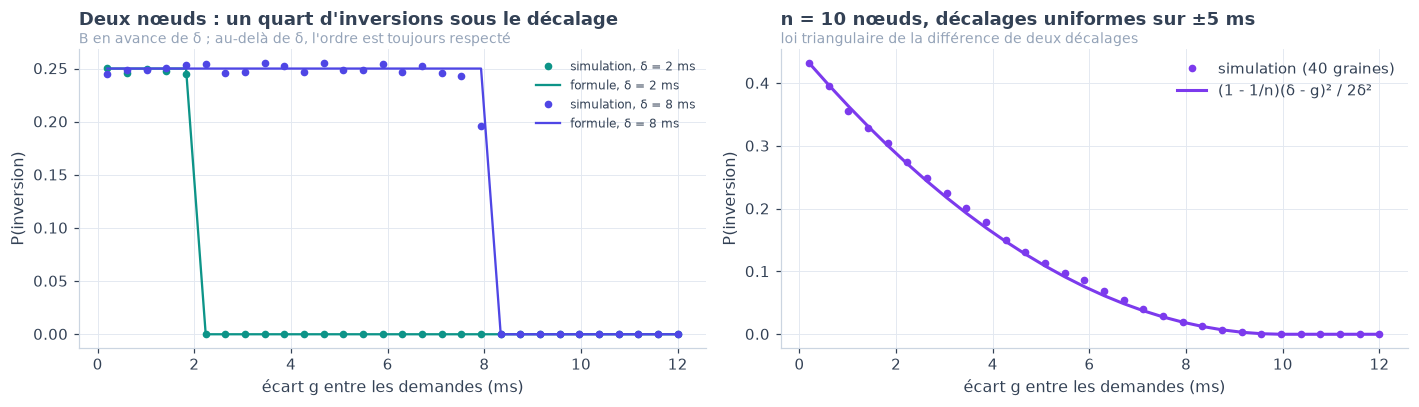

In [3]:
N = 200_000
times = np.sort(rng.uniform(0, 10.0, N))           # 20 000 demandes/s : écart réel ≈ g à 0,05 ms près
gaps = np.linspace(0.0002, 0.012, 30)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
for delta, c in [(0.002, TEAL), (0.008, INDIGO)]:
    nodes_ = rng.integers(0, 2, N)
    ids = cs.assign_ids("wallclock", times, nodes_, 2, offsets=[0.0, delta], tick=1e-5)
    ax.plot(gaps * 1000, cs.inversion_curve(times, ids, gaps, 20000, seed=1), "o", color=c, ms=4,
            label=f"simulation, δ = {delta * 1000:.0f} ms")
    ax.plot(gaps * 1000, 0.25 * (gaps < delta), "-", color=c, lw=1.5, label=f"formule, δ = {delta * 1000:.0f} ms")
ax.set_xlabel("écart g entre les demandes (ms)"); ax.set_ylabel("P(inversion)")
ax.set_title("Deux nœuds : un quart d'inversions sous le décalage")
subtitle(ax, "B en avance de δ ; au-delà de δ, l'ordre est toujours respecté")
ax.legend(fontsize=8)
delta, n = 0.010, 10
curves = []
for seed in range(40):
    g_ = np.random.default_rng(100 + seed)
    offs = g_.uniform(-delta / 2, delta / 2, n)
    nodes_ = g_.integers(0, n, N)
    ids = cs.assign_ids("wallclock", times, nodes_, n, offsets=offs, tick=1e-5)
    curves.append(cs.inversion_curve(times, ids, gaps, 5000, seed=seed))
ax2.plot(gaps * 1000, np.mean(curves, axis=0), "o", color=VIOLET, ms=4, label="simulation (40 graines)")
th = (1 - 1 / n) * np.clip(delta - gaps, 0, None) ** 2 / (2 * delta ** 2)
ax2.plot(gaps * 1000, th, color=VIOLET, label="(1 - 1/n)(δ - g)² / 2δ²")
ax2.set_xlabel("écart g entre les demandes (ms)"); ax2.set_ylabel("P(inversion)")
ax2.set_title("n = 10 nœuds, décalages uniformes sur ±5 ms")
subtitle(ax2, "loi triangulaire de la différence de deux décalages")
ax2.legend()
plt.tight_layout(); plt.show()

Les simulations suivent les formules. À écart nul, près d'une paire de demandes sur deux
(45 % avec 10 nœuds) est inversée : pour des événements rapprochés, un horodatage
physique ne vaut guère mieux qu'un tirage à pile ou face.

> **À retenir.** Avec des horodatages physiques, deux événements séparés de moins que le
> décalage des horloges sont ordonnés au hasard ; au-delà, l'ordre est correct. Le
> décalage borne la « résolution causale » du système.

## Exercice 10.8 : taille et placement d'une grappe de consensus face aux pannes corrélées

**Énoncé.** Chaque nœud est indisponible avec probabilité $p = 10^{-3}$, indépendamment ;
chaque zone de disponibilité (centre de données) tombe entièrement avec probabilité
$q = 5 \cdot 10^{-4}$. On compare :
(A) 3 nœuds dans 3 zones ; (B) 5 nœuds dans 3 zones (2, 2, 1) ; (C) 5 nœuds dans 2 zones
(3, 2) ; (D) 3 nœuds dans une seule zone ; (E) 4 nœuds dans 2 zones (2, 2).

1. Calculer exactement la probabilité que la grappe perde sa majorité.
2. Vérifier par Monte-Carlo. Conclusions ?

**Rappels.** Majorité stricte, $2f + 1$ nœuds (cours 3, section 2 ; section *Single-value consensus*),
pannes corrélées (chapitre 2).

**Solution.**

*1.* On conditionne sur l'état des zones : pour chaque combinaison de zones en panne
(probabilité $\prod q^{z}(1-q)^{1-z}$), les nœuds des zones vivantes sont chacun en vie avec
probabilité $1 - p$ ; la majorité est perdue si le nombre de nœuds vivants est inférieur à
$\lfloor n/2 \rfloor + 1$. On somme. Ordres de grandeur : dans (A) et (B), une zone perdue
ne suffit pas, il faut une zone **plus** une panne de nœud (environ $q \cdot 2p$) ou deux
zones ; dans (C), perdre la zone de 3 nœuds suffit (environ $q$) ; dans (D), la zone unique
aussi ; dans (E), 4 nœuds exigent 3 vivants : perdre une zone suffit (environ $2q$).

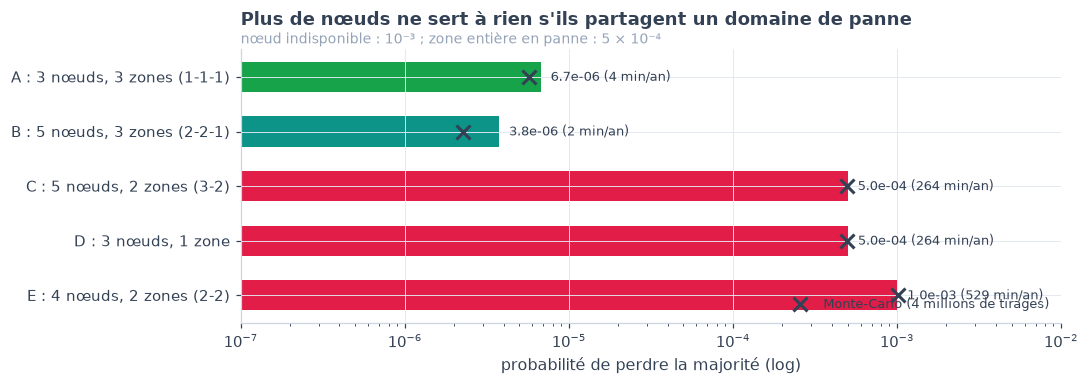

,exact,monte_carlo,minutes_par_an
config,,,
"A : 3 nœuds, 3 zones (1-1-1)",6.739e-06,5.750e-06,3.542
"B : 5 nœuds, 3 zones (2-2-1)",3.757e-06,2.250e-06,1.975
"C : 5 nœuds, 2 zones (3-2)",5.015e-04,4.982e-04,263.592
"D : 3 nœuds, 1 zone",5.030e-04,4.965e-04,264.375
"E : 4 nœuds, 2 zones (2-2)",1.006e-03,1.017e-03,528.615


In [4]:
def perte_majorite(zones, p=1e-3, q=5e-4):
    n = sum(zones); maj = n // 2 + 1; total = 0.0
    for etat in np.ndindex(*(2,) * len(zones)):              # 1 = zone en panne
        pz = np.prod([q if e else 1 - q for e in etat])
        vivants_possibles = sum(z for z, e in zip(zones, etat) if not e)
        perte = sum(comb(vivants_possibles, k) * (1 - p) ** k * p ** (vivants_possibles - k) for k in range(min(maj, vivants_possibles + 1)))
        total += pz * perte
    return total

def monte_carlo(zones, p=1e-3, q=5e-4, n_sim=4_000_000, seed=0):
    g = np.random.default_rng(seed)
    zone_ko = g.random((n_sim, len(zones))) < q
    vivants = np.zeros(n_sim, dtype=int)
    for j, z in enumerate(zones):
        vivants += np.where(zone_ko[:, j], 0, (g.random((n_sim, z)) >= p).sum(axis=1))
    return np.mean(vivants < sum(zones) // 2 + 1)

configs = {"A : 3 nœuds, 3 zones (1-1-1)": [1, 1, 1], "B : 5 nœuds, 3 zones (2-2-1)": [2, 2, 1],
           "C : 5 nœuds, 2 zones (3-2)": [3, 2], "D : 3 nœuds, 1 zone": [3], "E : 4 nœuds, 2 zones (2-2)": [2, 2]}
R = pd.DataFrame([dict(config=k, exact=perte_majorite(v), monte_carlo=monte_carlo(v)) for k, v in configs.items()]).set_index("config")
R["minutes_par_an"] = R.exact * 525_600
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(R.index[::-1], R.exact[::-1], color=[GREEN, TEAL, ROSE, ROSE, ROSE][::-1], height=0.55)
ax.plot(R.monte_carlo[::-1], range(len(R)), "x", color=SLATE, ms=9, mew=2, label="Monte-Carlo (4 millions de tirages)")
ax.set_xscale("log")
for i, (v, m) in enumerate(zip(R.exact[::-1], R.minutes_par_an[::-1])):
    ax.text(v * 1.15, i, f"{v:.1e} ({m:.0f} min/an)", va="center", fontsize=8.5)
ax.set_xlim(1e-7, 1e-2)
ax.set_xlabel("probabilité de perdre la majorité (log)")
ax.set_title("Plus de nœuds ne sert à rien s'ils partagent un domaine de panne")
subtitle(ax, "nœud indisponible : 10⁻³ ; zone entière en panne : 5 × 10⁻⁴")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()
R

Le calcul exact et la simulation concordent (aux fluctuations près pour les très petites
probabilités). (B) est la meilleure configuration : il faut perdre une zone et un autre
nœud, ou deux zones. (A) vient ensuite. (C), malgré ses 5 nœuds, est **75 fois pire** que
(A), aussi mauvaise que (D) : la zone de 3 nœuds porte la majorité à elle seule. (E) est la pire : un
nombre pair de nœuds répartis dans deux zones perd sa majorité avec n'importe quelle zone.

> **À retenir.** Ce qui compte n'est pas le nombre de nœuds mais le nombre de **domaines de
> panne** à perdre pour tomber sous la majorité : nombre impair de nœuds, répartis sur au
> moins trois zones, aucune zone ne détenant une majorité.

## Exercice 10.9 : casser Raft en supprimant la restriction d'élection

**Énoncé.** Dans `cs.RaftNode`, le paramètre `check_log=False` fait voter un nœud pour
n'importe quel candidat de mandat supérieur, sans comparer les journaux.

1. Reprendre le scénario du cours 4, section 6 : deux nœuds isolés pendant qu'une entrée
   `x=7` est validée par les trois autres, puis panne du leader au rétablissement.
   Exécuter 10 graines avec et sans la règle, et compter les entrées validées effacées.
2. Expliquer le mécanisme de la perte. Pourquoi les nœuds isolés ont-ils de bonnes chances
   d'être élus ?

**Rappels.** Mandats, quorums qui se recoupent, règle d'élection de Raft (cours 4,
sections 2 et 6).

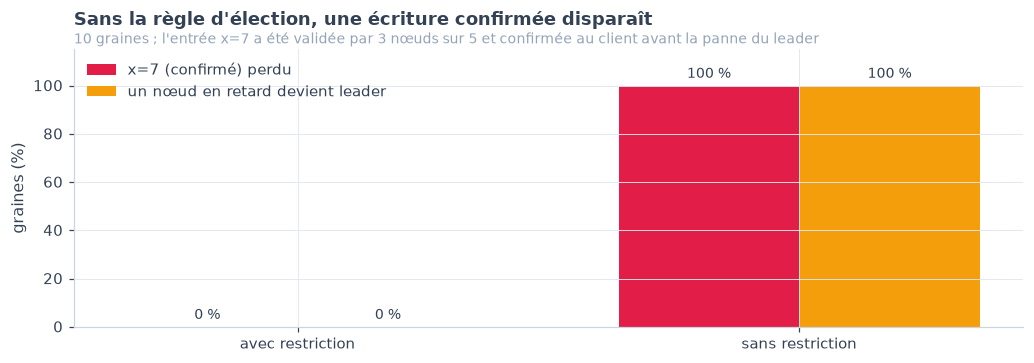

,règle,graine,isolés,nouveau_leader,x7_survit,effacées
0,avec restriction,0,"S1,S2",S4,True,0
1,avec restriction,1,"S1,S2",S4,True,0
2,avec restriction,2,"S1,S2",S4,True,0
3,avec restriction,3,"S2,S3",S5,True,0
4,avec restriction,4,"S1,S3",S5,True,0
5,avec restriction,5,"S1,S2",S5,True,0
6,avec restriction,6,"S1,S3",S4,True,0
7,avec restriction,7,"S1,S2",S3,True,0
8,avec restriction,8,"S1,S3",S4,True,0
9,avec restriction,9,"S2,S3",S5,True,0


In [5]:
def scenario(check_log, seed):
    net, nodes, trace = cs.raft_cluster(5, seed=seed, check_log=check_log)
    hist = []
    net.run(until=60)
    L = [x for x, n in nodes.items() if n.role == "leader"][0]
    autres = [x for x in nodes if x != L]
    for x in autres[:2]:
        net.partition({x}, set(nodes) - {x})
    net.add(cs.RaftClient("client", [L], [(1, "write", 7)], history=hist, timeout=50))
    net.run(until=100)
    termes = {x: nodes[x].term for x in nodes}
    net.heal(); net.crash(L)
    net.run(until=400)
    nouveau = [x for x, n in nodes.items() if n.role == "leader" and n.up][0]
    survit = all(any(e.cmd == ("set", "x", 7) for e in nodes[x].log) for x in nodes if x != L)
    s = cs.raft_check_safety(nodes, trace)
    return dict(règle="avec restriction" if check_log else "sans restriction", graine=seed,
                confirmé_au_client=bool(hist), isolés=",".join(autres[:2]), nouveau_leader=nouveau,
                nouveau_leader_isolé=nouveau in autres[:2], x7_survit=survit, effacées=s["entrees_validees_effacees"])

E9 = pd.DataFrame([scenario(c, s) for c in (True, False) for s in range(10)])
fig, ax = plt.subplots(figsize=(9.5, 3.4))
g = E9.groupby("règle").agg(perte=("x7_survit", lambda v: (~v).mean() * 100), isole=("nouveau_leader_isolé", lambda v: v.mean() * 100))
x = np.arange(len(g))
ax.bar(x - 0.18, g.perte, 0.36, color=ROSE, label="x=7 (confirmé) perdu")
ax.bar(x + 0.18, g.isole, 0.36, color=AMBER, label="un nœud en retard devient leader")
annotate_bars(ax, "{:.0f} %")
ax.set_xticks(x, g.index); ax.set_ylim(0, 115); ax.set_ylabel("graines (%)")
ax.set_title("Sans la règle d'élection, une écriture confirmée disparaît")
subtitle(ax, "10 graines ; l'entrée x=7 a été validée par 3 nœuds sur 5 et confirmée au client avant la panne du leader")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
E9[["règle", "graine", "isolés", "nouveau_leader", "x7_survit", "effacées"]].head(12)

**Solution.**

*1.* Avec la règle, `x=7` survit dans les 10 graines. Sans elle, il disparaît dans toutes :
un nœud isolé (au journal plus court) devient leader et impose son journal, ce qui efface
des entrées pourtant validées (compteur `effacées` > 0, propriété de sûreté violée).

*2.* Pendant leur isolement, les deux nœuds ont enchaîné les candidatures sans succès, et
leur **mandat** a grimpé bien au-dessus de celui des autres. Au rétablissement, leur
`RequestVote` porte un mandat supérieur : sans comparaison des journaux, les autres nœuds
votent pour eux (premier vote du mandat). Deux isolés plus un nœud suffisent pour une
majorité de 3. Le nouveau leader réplique alors son journal, sans `x=7` : la vérification
de cohérence d'`AppendEntries` fait **tronquer** les journaux des suiveurs. La règle
d'élection empêche cela : tout candidat doit obtenir le vote d'au moins un des trois nœuds
qui détiennent `x=7` (les majorités se recoupent), et ce nœud refuse un journal moins à
jour que le sien.

> **À retenir.** La sûreté d'un consensus repose sur des détails : une seule comparaison
> de journaux à l'élection sépare un système sûr d'un système qui perd des écritures
> confirmées. D'où le conseil du livre : utiliser un algorithme éprouvé, pas une
> bascule maison.

## Exercice 10.10 : régler le délai d'élection

**Énoncé.** Une grappe Raft de 5 nœuds envoie un battement toutes les 1,5 unités. Le délai
d'élection est tiré dans $[T, 2T]$. Les délais réseau sont log-normaux de médiane 1.

1. Avant de simuler : que se passe-t-il si $T$ est trop petit ? trop grand ?
2. Pour $T \in \{3, 4, 5, 8, 12, 20, 30\}$ et $\sigma \in \{0{,}3 ; 1{,}0 ; 1{,}3\}$, simuler
   2 000 unités de temps avec trois pannes du leader, et mesurer le **temps total sans
   leader** (après la première élection). Quel $T$ choisir ?

**Rappels.** Délais d'expiration, élections inutiles, pannes du leader (cours 4,
sections 3 et 7 ; section *Pros and cons of consensus*).

**Solution.**

*1.* Trop petit : un battement en retard (ou perdu) suffit à déclencher une élection, le
leader vivant est destitué, et les élections peuvent se succéder (plusieurs candidats se
réveillent en même temps, se partagent les votes et recommencent). Trop grand : après une
vraie panne, la grappe attend en moyenne $1{,}5\,T$ avant de réagir. On s'attend à une
courbe en U dont le minimum se déplace vers la droite quand la dispersion augmente.

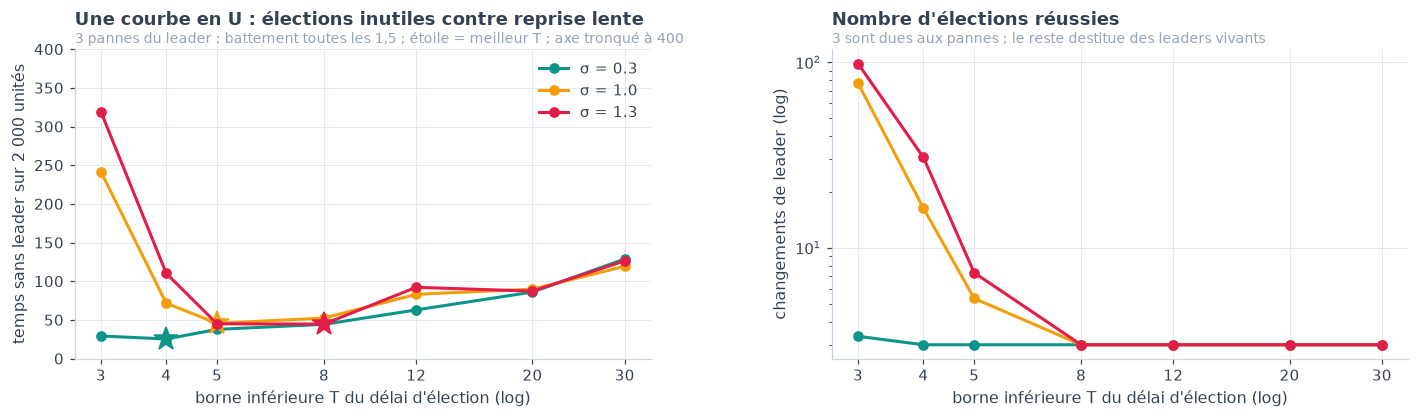

sigma,0.3,1.0,1.3
T,,,
3,29.500,241.917,319.667
4,25.667,71.750,110.417
5,38.083,45.917,45.250
8,44.583,52.750,44.917
12,63.250,83.417,92.500
20,86.333,90.083,87.500
30,129.083,119.583,126.667


In [6]:
def temps_sans_leader(trace, t_end, step=0.25):
    ev = sorted(trace, key=lambda e: e["t"])
    t_start = next(e["t"] for e in ev if e["kind"] == "leader")
    leaders, maxterm, k, tot = {}, 0, 0, 0.0
    for t in np.arange(0, t_end, step):
        while k < len(ev) and ev[k]["t"] <= t:
            e = ev[k]; k += 1
            maxterm = max(maxterm, e["term"])
            if e["kind"] == "leader":
                leaders[e["node"]] = e["term"]
            elif e["kind"] in ("step_down", "crash"):
                leaders.pop(e["node"], None)
        if t >= t_start and not any(term == maxterm for term in leaders.values()):
            tot += step
    return tot

rows = []
for sigma in (0.3, 1.0, 1.3):
    for T in (3, 4, 5, 8, 12, 20, 30):
        for seed in range(3):
            net, nodes, trace = cs.raft_cluster(5, seed=seed, latency=cs.lognormal_latency(1.0, sigma),
                                                election_timeout=(T, 2 * T), heartbeat=1.5)
            def tue():
                ls = [x for x, n in nodes.items() if n.role == "leader" and n.up]
                if ls:
                    net.crash(ls[0]); net.at(net.now + 50, net.recover, ls[0])
            for tc in (500, 1000, 1500):
                net.at(tc, tue)
            net.run(until=2000)
            rows.append(dict(sigma=sigma, T=T, sans_leader=temps_sans_leader(trace, 2000),
                             elections=len(cs.raft_leaders(trace)) - 1))
E10 = pd.DataFrame(rows).groupby(["sigma", "T"]).mean().reset_index()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.9))
for sigma, c in zip((0.3, 1.0, 1.3), (TEAL, AMBER, ROSE)):
    s_ = E10[E10.sigma == sigma]
    ax.plot(s_["T"], s_.sans_leader, "o-", color=c, label=f"σ = {sigma}")
    ax2.plot(s_["T"], s_.elections, "o-", color=c, label=f"σ = {sigma}")
    best = s_.loc[s_.sans_leader.idxmin()]
    ax.plot(best["T"], best.sans_leader, "*", color=c, ms=16)
ax.axhline(0, color=GRAY, lw=0.5)
for a in (ax, ax2):
    a.set_xscale("log"); a.minorticks_off()
    a.set_xticks([3, 4, 5, 8, 12, 20, 30], ["3", "4", "5", "8", "12", "20", "30"])
ax.set_ylim(0, 400)
ax.set_xlabel("borne inférieure T du délai d'élection (log)"); ax.set_ylabel("temps sans leader sur 2 000 unités")
ax.set_title("Une courbe en U : élections inutiles contre reprise lente")
subtitle(ax, "3 pannes du leader ; battement toutes les 1,5 ; étoile = meilleur T ; axe tronqué à 400")
ax.legend()
ax2.set_yscale("log")
ax2.set_xlabel("borne inférieure T du délai d'élection (log)"); ax2.set_ylabel("changements de leader (log)")
ax2.set_title("Nombre d'élections réussies")
subtitle(ax2, "3 sont dues aux pannes ; le reste destitue des leaders vivants")
plt.tight_layout(); plt.show()
E10.pivot(index="T", columns="sigma", values="sans_leader")

*2.* Avec des délais réseau réguliers ($\sigma = 0{,}3$), la courbe est presque croissante
(minimum à $T = 4$) : on peut choisir un délai court (il ne reste que le coût des trois reprises, proportionnel à $T$).
Quand la dispersion augmente, les délais courts provoquent des dizaines d'élections inutiles
et des centaines d'unités sans leader ; le minimum se déplace vers $T \approx 5$ (σ = 1), puis
entre 5 et 8 (σ = 1,3), alors que $T = 3$ coûte 240 à 320 unités sans leader. Règle pratique : un délai d'élection de l'ordre de **plusieurs fois le
temps d'aller-retour en queue de distribution** (p99), bien au-dessus de l'intervalle des
battements, et pas davantage.

> **À retenir.** Le délai d'élection arbitre entre fausses détections et lenteur de reprise ;
> son bon réglage dépend de la queue de distribution des délais réseau, pas de leur moyenne.

## Exercice 10.11 : horloges logiques hybrides

**Énoncé.**

1. À la main (résolution 1 ms, horodatage (l, c)) : le nœud A, dont l'horloge physique lit
   100, envoie un message. Le nœud B le reçoit quand son horloge lit 96, puis émet deux
   événements locaux quand elle lit 97 puis 101. Enfin l'horloge de B recule à 99 (NTP) et
   B émet un événement. Donner les horodatages.
2. Simuler la messagerie du cours 2 avec des décalages d'horloges de plus en plus grands et
   mesurer l'avance maximale de la HLC sur l'horloge physique de chaque nœud ; la comparer au
   décalage maximal. Vérifier qu'aucune paire causale n'est inversée.

**Rappels.** Horloges logiques hybrides (cours 2, section 7 ; section *Hybrid logical
clocks*).

**Solution.**

*1.* A émet (100, 0). B reçoit à 96 : $l = \max(l_B, 100, 96) = 100$, égal au $l$ reçu :
$c = 0 + 1$ → (100, 1). Événement à 97 : $97 < l$, donc $l$ reste 100 et $c = 2$ → (100, 2).
Événement à 101 : $101 > l$ → (101, 0). Recul à 99 : $99 < 101$ → (101, 1) : l'horodatage
reste monotone malgré le recul.

*2.* La HLC d'un nœud ne dépasse son horloge physique que d'une quantité bornée par
l'avance du nœud le plus en avance dont il a reçu (directement ou transitivement) un
horodatage, donc par le décalage maximal entre horloges.

,événement,l,c
0,A émet,100,0
1,B reçoit,100,1
2,B local à 97,100,2
3,B local à 101,101,0
4,B local après recul à 99,101,1


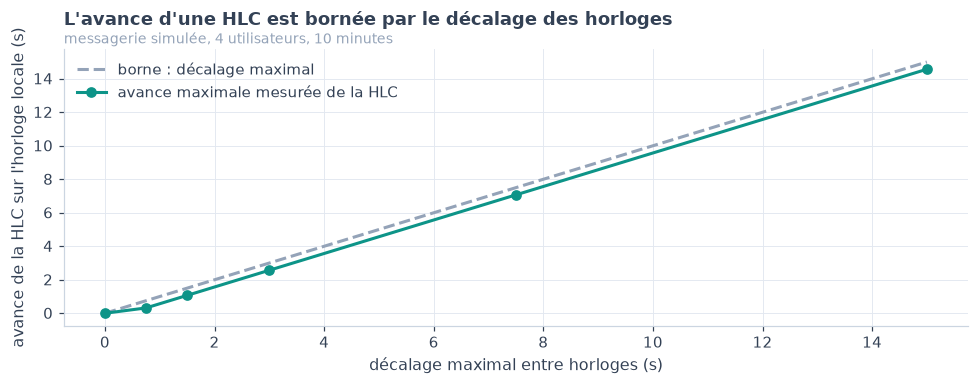

,décalage_max,avance_max_hlc,inversions_hlc,inversions_physique
0,0.00,-4.570e-06,0,0
1,0.75,3.187e-01,0,7
2,1.50,1.069e+00,0,19
3,3.00,2.569e+00,0,57
4,7.50,7.069e+00,0,180
5,15.00,1.457e+01,0,394


In [7]:
from ddia.consistency_clocks import HybridLogicalClock, hlc_factory

horloge = {"A": 100.0, "B": 96.0}
A = HybridLogicalClock("A", lambda: horloge["A"], resolution=1.0)
B = HybridLogicalClock("B", lambda: horloge["B"], resolution=1.0)
trace_ = [("A émet", A.send())]
trace_.append(("B reçoit", B.recv(trace_[0][1])))
horloge["B"] = 97.0; trace_.append(("B local à 97", B.send()))
horloge["B"] = 101.0; trace_.append(("B local à 101", B.send()))
horloge["B"] = 99.0; trace_.append(("B local après recul à 99", B.send()))
display(pd.DataFrame([dict(événement=k, l=v[0], c=v[1]) for k, v in trace_]))

rows = []
for skew in (0.0, 0.5, 1.0, 2.0, 5.0, 10.0):
    offs = [0.0, skew, -skew / 2, skew / 4]
    ev = cs.run_chat(n_users=4, duration=600, rate=0.02, reply_prob=0.25, think=4.0, offsets=offs, latency=(0.2, 1.5),
                     seed=3, extra_clocks={"hlc": hlc_factory(1e-3)})
    avance = max(e["hlc"][0] * 1e-3 - e["t_phys"] for e in ev)
    rows.append(dict(décalage_max=max(offs) - min(offs), avance_max_hlc=avance,
                     inversions_hlc=cs.causal_order_errors(ev, "hlc")["inversées"],
                     inversions_physique=cs.causal_order_errors(ev, "t_phys")["inversées"]))
H11 = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(H11.décalage_max, H11.décalage_max, "--", color=GRAY, label="borne : décalage maximal")
ax.plot(H11.décalage_max, H11.avance_max_hlc, "o-", color=TEAL, label="avance maximale mesurée de la HLC")
ax.set_xlabel("décalage maximal entre horloges (s)"); ax.set_ylabel("avance de la HLC sur l'horloge locale (s)")
ax.set_title("L'avance d'une HLC est bornée par le décalage des horloges")
subtitle(ax, "messagerie simulée, 4 utilisateurs, 10 minutes")
ax.legend()
plt.tight_layout(); plt.show()
H11

L'avance mesurée reste sous la diagonale (elle l'atteint presque : le nœud le plus en
retard reçoit vite un message du plus en avance) et la HLC ne commet aucune inversion
causale, contrairement à l'horloge physique dès que les horloges divergent.

> **À retenir.** Une HLC est monotone même si l'horloge physique recule, cohérente avec la
> causalité, et ne s'écarte de l'heure physique que du décalage entre horloges.

## Exercice 10.12 : la photo privée, horloges logiques contre générateur linéarisable

**Énoncé.** Un utilisateur rend son compte privé (écriture A dans la base des comptes),
puis, $g$ ms plus tard, publie une photo (écriture B dans la base des photos). Les deux
bases ne communiquent pas entre elles. On compare trois façons d'horodater :

- horloges de **Lamport** propres à chaque base, dont les compteurs avancent avec leur
  trafic local : 1 000 écritures/s dans la base des comptes, 100/s dans celle des photos ;
- **HLC** dans chaque base, horloges physiques décalées uniformément de ±5 ms ;
- un **oracle d'horodatage** linéarisable commun.

1. Pour chaque méthode, estimer en fonction de $g$ la probabilité que B reçoive un
   horodatage **inférieur** à A (la photo est alors visible dans un instantané qui voit le
   compte encore public).
2. Spanner obtient la même garantie que l'oracle en attendant la fin de l'intervalle
   d'incertitude $[t - \varepsilon, t + \varepsilon]$ de ses horloges avant de valider. Pour
   $\varepsilon \in \{1 ; 3{,}5 ; 7\}$ ms, que coûte cette attente en latence, et quel débit
   maximal pour des écritures successives d'un même client ?

**Rappels.** Générateurs linéarisables, oracle d'horodatage, attente de l'incertitude
(cours 2, section 8 ; section *Linearizable ID Generators*).

**Solution.**

*1.* **Lamport** : les compteurs ne se synchronisent jamais ; après $t$ secondes, celui des
comptes vaut environ $1\,000\,t$ et celui des photos $100\,t$ : B a presque toujours un
compteur plus petit, quel que soit $g$ (probabilité proche de 1). **HLC** : sans
communication, chaque HLC suit son horloge physique ; inversion si
$o_{\text{comptes}} - o_{\text{photos}} > g$, soit $(\delta - g)^2 / (2\delta^2)$ avec
$\delta = 10$ ms (exercice 10.7), nulle au-delà de 10 ms. **Oracle** : jamais (B commence
après la fin de A).

*2.* Chaque validation attend environ $2\varepsilon$ (l'intervalle doit être entièrement
passé) : 2, 7 ou 14 ms de latence en plus. Des écritures **successives** d'un même client
(chacune attendant la précédente) plafonnent donc à $1/(2\varepsilon)$ : 500, 143 ou 71 par
seconde ; des écritures indépendantes, elles, se recouvrent et ne sont pas limitées ainsi.

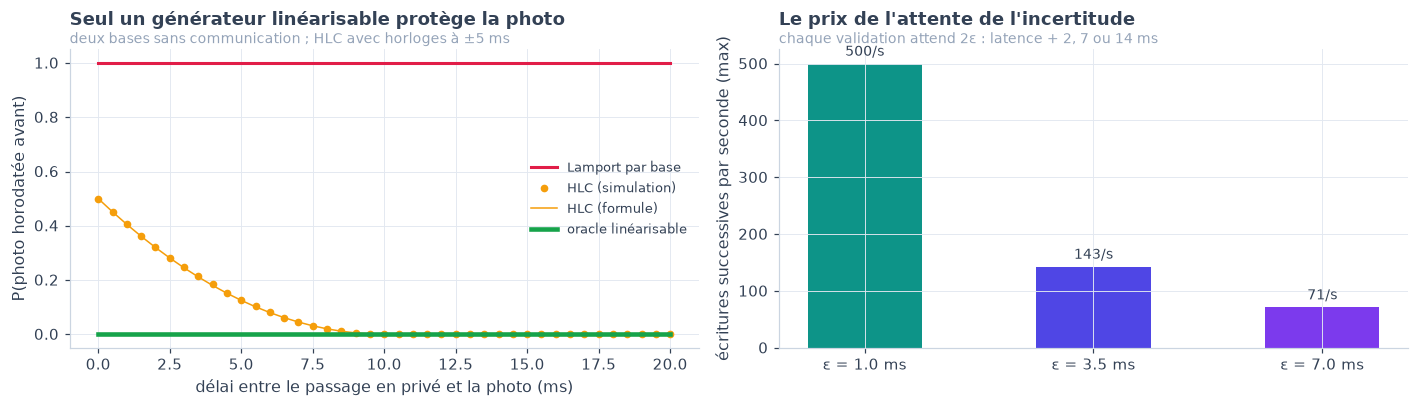

In [8]:
g_ms = np.linspace(0, 20, 41)
n = 20_000
t_debut = rng.uniform(10, 100, n)                     # instant de l'écriture A (s), après un temps de fonctionnement
p_lamport, p_hlc = [], []
o1, o2 = rng.uniform(-5, 5, n), rng.uniform(-5, 5, n)  # décalages (ms)
for g in g_ms:
    ts_a = rng.poisson(1000 * t_debut) + 1
    ts_b = rng.poisson(100 * (t_debut + g / 1000)) + 1
    p_lamport.append(np.mean(ts_b < ts_a))
    p_hlc.append(np.mean(t_debut * 1000 + g + o2 < t_debut * 1000 + o1))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.plot(g_ms, p_lamport, color=ROSE, label="Lamport par base")
ax.plot(g_ms, p_hlc, "o", color=AMBER, ms=4, label="HLC (simulation)")
ax.plot(g_ms, np.clip(10 - g_ms, 0, None) ** 2 / 200, color=AMBER, lw=1, label="HLC (formule)")
ax.plot(g_ms, np.zeros_like(g_ms), color=GREEN, lw=3, label="oracle linéarisable")
ax.set_xlabel("délai entre le passage en privé et la photo (ms)"); ax.set_ylabel("P(photo horodatée avant)")
ax.set_title("Seul un générateur linéarisable protège la photo")
subtitle(ax, "deux bases sans communication ; HLC avec horloges à ±5 ms")
ax.legend(fontsize=8.5)
eps = np.array([1, 3.5, 7])
ax2.bar([f"ε = {e} ms" for e in eps], 1000 / (2 * eps), color=[TEAL, INDIGO, VIOLET], width=0.5)
annotate_bars(ax2, "{:.0f}/s")
ax2.set_ylabel("écritures successives par seconde (max)")
ax2.set_title("Le prix de l'attente de l'incertitude")
subtitle(ax2, "chaque validation attend 2ε : latence + 2, 7 ou 14 ms")
plt.tight_layout(); plt.show()

Avec des horloges de Lamport sans communication, la photo est horodatée avant le passage en
privé dans pratiquement 100 % des cas : la base des photos, moins active, a un compteur bien
plus petit. Les HLC réduisent le problème aux actions plus rapprochées que le décalage des
horloges (et un utilisateur qui change d'appareil met en général plus de 10 ms...), mais ne
l'éliminent pas. L'oracle l'élimine, au prix d'un aller-retour vers un nœud unique ; Spanner
l'élimine sans nœud central, au prix de $2\varepsilon$ d'attente par validation, d'où
l'intérêt de réduire $\varepsilon$ par du matériel (GPS, horloges atomiques).

> **À retenir.** La causalité ne suffit pas quand deux actions sont liées par un canal
> extérieur au système (le même utilisateur sur deux appareils) : il faut un ordre
> linéarisable, obtenu par un point central (oracle) ou par l'attente d'une incertitude
> d'horloge bornée (Spanner).